In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, save_img
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, Add, Input, MaxPooling2D
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [ ]:
BASE_DIR = "/content/drive/MyDrive/RiceLeafDisease12classes"

TRAIN_DIR = BASE_DIR + "/train"
VAL_DIR   = BASE_DIR + "/validation"

IMG_SIZE = (224,224)
TARGET_SIZE = 1000

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8,1.2],
    fill_mode='nearest'
)

for class_name in os.listdir(TRAIN_DIR):

    # ❌ Skip irrelevant class
    if class_name == "irrelevant_pics":
        print("Skipping irrelevant_pics")
        continue

    class_path = os.path.join(TRAIN_DIR, class_name)

    images = os.listdir(class_path)
    num_images = len(images)

    print(f"{class_name}: {num_images}")

    i = 0
    while num_images < TARGET_SIZE:

        img_name = images[i % len(images)]
        img_path = os.path.join(class_path, img_name)

        try:
            img = load_img(img_path, target_size=IMG_SIZE)
            x = img_to_array(img)
            x = np.expand_dims(x, axis=0)

            aug_iter = datagen.flow(x, batch_size=1)
            aug_img = next(aug_iter)[0].astype('uint8')

            new_name = f"aug_{num_images}.jpg"
            save_img(os.path.join(class_path, new_name), aug_img)

            num_images += 1

        except:
            pass

        i += 1

    print(f"Done {class_name} → {num_images}")

leaf_blast: 1000
Done leaf_blast → 1000
Ragged Stunt Virus: 1000
Done Ragged Stunt Virus → 1000
leaf_scald: 1000
Done leaf_scald → 1000
Skipping irrelevant_pics
healthy: 1000
Done healthy → 1000
Hispa: 1000
Done Hispa → 1000
brown_spot: 1000
Done brown_spot → 1000
Stem Rot: 1000
Done Stem Rot → 1000
Tungro: 1000
Done Tungro → 1000
bacterial_leaf_blight: 1000
Done bacterial_leaf_blight → 1000
narrow_brown_spot: 1000
Done narrow_brown_spot → 1000
Sheath Rot: 1000
Done Sheath Rot → 1000


In [ ]:
BATCH_SIZE = 32

train_gen = ImageDataGenerator(rescale=1./255)
val_gen   = ImageDataGenerator(rescale=1./255)

train_generator = train_gen.flow_from_directory(
    TRAIN_DIR,
    target_size=(224,224),
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_generator = val_gen.flow_from_directory(
    VAL_DIR,
    target_size=(224,224),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
NUM_CLASSES = len(class_names)

print(class_names)

Found 11996 images belonging to 12 classes.
Found 1413 images belonging to 12 classes.
['Hispa', 'Ragged Stunt Virus', 'Sheath Rot', 'Stem Rot', 'Tungro', 'bacterial_leaf_blight', 'brown_spot', 'healthy', 'irrelevant_pics', 'leaf_blast', 'leaf_scald', 'narrow_brown_spot']


In [ ]:
def residual_block(x, filters, stride=1):

    shortcut = x

    x = Conv2D(filters, 3, strides=stride, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = Conv2D(filters, 3, padding="same")(x)
    x = BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, 1, strides=stride, padding="same")(shortcut)
        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation("relu")(x)

    return x

In [ ]:
inputs = Input(shape=(224,224,3))

x = Conv2D(64, 7, strides=2, padding="same")(inputs)
x = BatchNormalization()(x)
x = Activation("relu")(x)
x = MaxPooling2D(3, strides=2, padding="same")(x)

x = residual_block(x, 64)
x = residual_block(x, 64)

x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

x = residual_block(x, 256, stride=2)
x = residual_block(x, 256)

x = residual_block(x, 512, stride=2)
x = residual_block(x, 512)

x = GlobalAveragePooling2D()(x)

x = Dense(512, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
EPOCHS = 200

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS
)

Epoch 1/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 2764s 7s/step - accuracy: 0.6560 - loss: 1.0900 - val_accuracy: 0.1288 - val_loss: 5.7566
Epoch 2/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 67s 178ms/step - accuracy: 0.7859 - loss: 0.6314 - val_accuracy: 0.5633 - val_loss: 2.6475
Epoch 3/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 68s 181ms/step - accuracy: 0.8374 - loss: 0.4945 - val_accuracy: 0.7473 - val_loss: 0.9543
Epoch 4/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 69s 183ms/step - accuracy: 0.8722 - loss: 0.3774 - val_accuracy: 0.7233 - val_loss: 1.1577
Epoch 5/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 69s 183ms/step - accuracy: 0.8862 - loss: 0.3345 - val_accuracy: 0.6306 - val_loss: 1.9800
Epoch 6/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 71s 189ms/step - accuracy: 0.9027 - loss: 0.2828 - val_accuracy: 0.6921 - val_loss: 1.7168
Epoch 7/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 70s 186ms/step - accuracy: 0.9191 - loss: 0.2352 - val_accuracy: 0.9151 - val_loss: 0.2566
Epoch 8/200
375/375 ━━━━━━━━━━━━━━━━━━━━ 68s 182ms/step - accuracy: 0.9234 - 

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

pred = model.predict(val_generator)

y_pred = np.argmax(pred, axis=1)
y_true = val_generator.classes

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

45/45 ━━━━━━━━━━━━━━━━━━━━ 15s 280ms/step
Accuracy: 0.9766454352441614

Classification Report:

                       precision    recall  f1-score   support

                Hispa       1.00      1.00      1.00        88
   Ragged Stunt Virus       1.00      1.00      1.00        88
           Sheath Rot       1.00      1.00      1.00        81
             Stem Rot       1.00      1.00      1.00        88
               Tungro       1.00      1.00      1.00        88
bacterial_leaf_blight       1.00      1.00      1.00        88
           brown_spot       0.85      0.91      0.88        88
              healthy       0.91      0.90      0.90        88
      irrelevant_pics       1.00      1.00      1.00       452
           leaf_blast       0.89      0.82      0.85        88
           leaf_scald       1.00      1.00      1.00        88
    narrow_brown_spot       0.98      1.00      0.99        88

             accuracy                           0.98      1413
            macro av

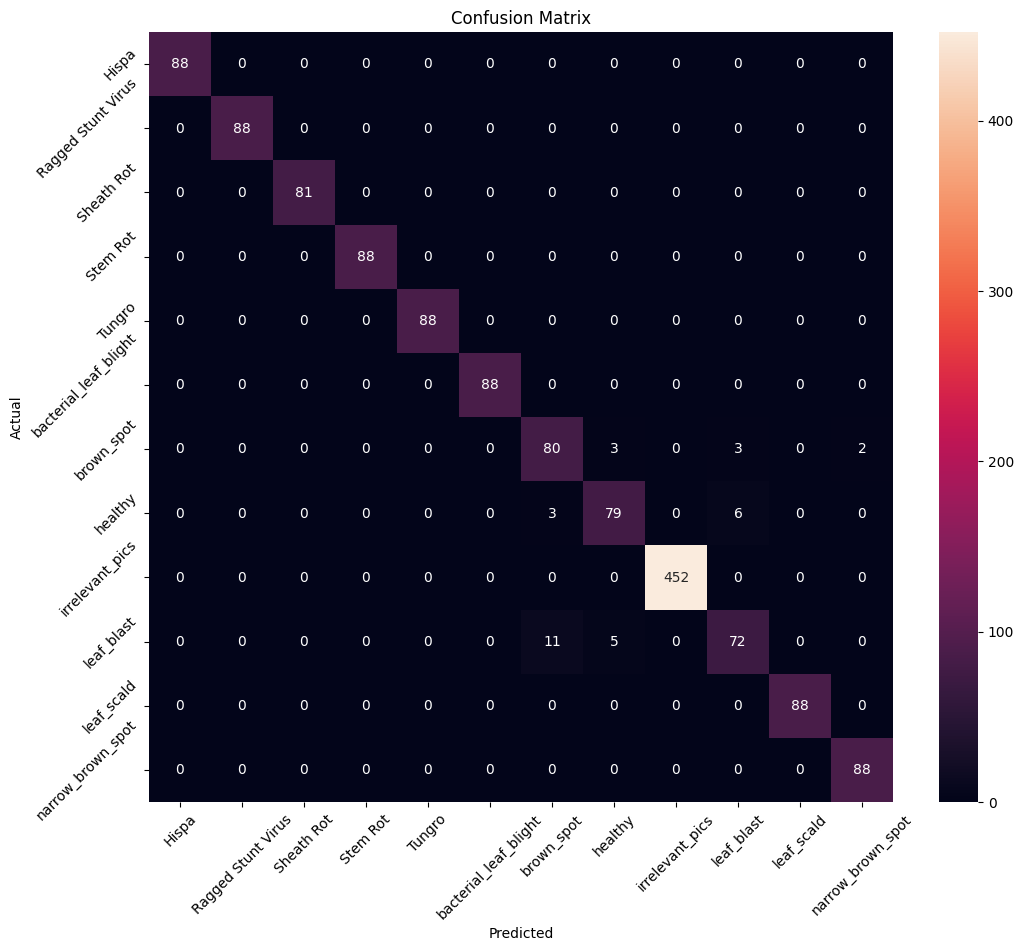

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()

In [ ]:
model.save("/content/drive/MyDrive/rice_resnet_final_experiment_4.h5")

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving healthy rice.jpeg to healthy rice.jpeg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


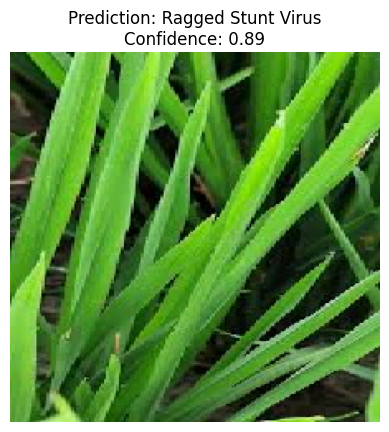

Predicted Class: Ragged Stunt Virus
Confidence: 0.89305544


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

for img_name in uploaded.keys():

    img_path = img_name

    # Load & preprocess
    img = image.load_img(img_path, target_size=(224,224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    prediction = model.predict(img_array)

    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction)

    # Display
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}")
    plt.axis("off")
    plt.show()

    print("Predicted Class:", predicted_class)
    print("Confidence:", confidence)